# 통계값과 분포

분석 목적 → 데이터 이해 → 요약 → 해석 순서로 진행합니다. CRISP-DM에서는 업무 이해와 데이터 이해가 먼저입니다. 통계는 불확실성을 설명하고, 마이닝은 패턴을 찾고, ML/DL은 예측·표현 학습에 활용합니다. 큰 데이터도 표본 편향을 없애 주지는 않습니다.

**학습 목표:** 기술통계와 추론통계, 평균·중앙값·최빈값, 편차·분산·표준편차, 사분위수·IQR·이상치 후보, 같은 평균, 다른 분포

공식 → 직접 구현 또는 계산 → 라이브러리 대조 → 해석 순서로 학습합니다.

## 실행 준비

Python 3.11 이상, NumPy·pandas·SciPy·Matplotlib이 필요합니다. 없는 경우 별도 셀에서 `%pip install numpy pandas scipy matplotlib`을 한 번 실행하세요. 새 커널에서 위에서 아래로 실행합니다. 외부 데이터 다운로드는 없습니다. 그래프는 폰트 호환을 위해 영문 제목을 쓰고 해석은 한국어로 제공합니다.

**표기:** 기본 기술 분산은 ddof=0, 모집단 분산 추정·평균 추론은 ddof=1을 명시합니다. 난수는 seed=42(문제에 지정 시 해당 seed)입니다.

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
# 외부 파일 없이 재현 가능한 학습용 가상 자료
x = np.array([12, 15, 14, 10, 18, 20, 22, 25, 30, 28], dtype=float)
y = np.array([2, 4, 6, 8, 10, 12, 14, 40], dtype=float)
plt.rcParams['axes.unicode_minus'] = False


Matplotlib is building the font cache; this may take a moment.


## 1. 기술통계와 추론통계

기술통계는 관찰한 자료를 요약합니다. 추론통계는 표본에서 모집단으로 범위를 넓히므로 대표성과 불확실성을 따져야 합니다. 값 하나는 관측값, 관심 대상 전체는 모집단, 조사한 일부는 표본입니다. 명목척도(지역)는 빈도, 서열척도(만족도)는 순서, 등간척도(섭씨)는 차이, 비율척도(매출)는 비율 해석이 가능합니다.

In [2]:
labels = ['A','A','B','C','A']
print(Counter(labels))
print(pd.Series(labels).value_counts(normalize=True))

Counter({'A': 3, 'B': 1, 'C': 1})
A    0.6
B    0.2
C    0.2
Name: proportion, dtype: float64


**해석 포인트:** 등급에는 순서가 있지만 등급 사이 간격은 일정한 숫자가 아닙니다. 편의 표본 6명만으로 전체 고객 비율을 확정할 수 없습니다.

**직접 확인:** 대응 실습의 문제 1에서 다른 입력으로 적용해 보세요.

## 2. 평균·중앙값·최빈값

평균은 합/n입니다. 중앙값은 정렬 후 가운데 값(짝수이면 두 값의 평균), 최빈값은 가장 잦은 값이며 여러 개일 수 있습니다. 평균은 극단값에 민감합니다. 중앙값도 자료가 바뀌면 변할 수 있으므로 극단값에 전혀 영향받지 않는다고 단정하지 않습니다.

In [3]:
def mean_manual(a):
    if len(a)==0: raise ValueError('빈 자료')
    return sum(a)/len(a)
def median_manual(a):
    if len(a)==0: raise ValueError('빈 자료')
    b=sorted(a); n=len(b)
    return b[n//2] if n%2 else (b[n//2-1]+b[n//2])/2
print(mean_manual(x), np.mean(x))
print(median_manual(x), np.median(x))
assert np.isclose(mean_manual(x), np.mean(x))

19.4 19.4
19.0 19.0


**해석 포인트:** 평균 12, 중앙값 9입니다. 모든 값이 1번이므로 모든 값이 공동 최빈값입니다. 400으로 바꾸면 평균은 57, 중앙값은 9로 유지됩니다.

**직접 확인:** 대응 실습의 문제 2에서 다른 입력으로 적용해 보세요.

## 3. 편차·분산·표준편차

편차는 값−평균이며 합은 부동소수점 오차를 제외하면 0입니다. 모분산은 편차제곱합/n, 모집단 분산을 추정하는 표본분산은 /(n−1)입니다. NumPy 기본 ddof=0, pandas Series.var 기본 ddof=1입니다. 표준편차는 분산의 제곱근으로 원래 단위를 가집니다.

In [4]:
def variance_manual(a, ddof=1):
    if ddof not in (0,1) or len(a)<=ddof: raise ValueError('표본 크기와 ddof 확인')
    m=sum(a)/len(a)
    return sum((v-m)**2 for v in a)/(len(a)-ddof)
print(x-x.mean())
for d in (0,1):
    print(d, variance_manual(x,d), np.var(x,ddof=d))
    assert np.isclose(variance_manual(x,d),np.var(x,ddof=d))

[-7.4 -4.4 -5.4 -9.4 -1.4  0.6  2.6  5.6 10.6  8.6]
0 41.84 41.84
1 46.488888888888894 46.488888888888894


**해석 포인트:** 평균 4, 편차 [-2,0,2], 제곱 [4,0,4]입니다. 모분산 8/3, 표본분산 4이므로 표준편차도 달라집니다. 자료를 전체로 기술하는지 모집단을 추정하는지 먼저 정합니다.

**직접 확인:** 대응 실습의 문제 3에서 다른 입력으로 적용해 보세요.

## 4. 사분위수·IQR·이상치 후보

범위=max−min, IQR=Q3−Q1은 가운데 50%의 퍼짐입니다. 분위수는 보간 방식에 따라 달라질 수 있어 여기서는 NumPy method=linear를 씁니다. Q1−1.5IQR보다 작거나 Q3+1.5IQR보다 크면 이상치 후보입니다. 오류인지 실제 특이 사례인지 조사하며 자동 삭제하지 않습니다.

In [5]:
q1,q3=np.quantile(x,[.25,.75],method='linear'); iqr=q3-q1
print(q1,q3,iqr, x.max()-x.min())
print(x[(x<q1-1.5*iqr)|(x>q3+1.5*iqr)])

14.25 24.25 10.0 20.0
[]


**해석 포인트:** Q1=5.5, Q3=12.5, IQR=7, 경계 −5와 23, 후보는 40입니다. 엄격한 부등호 기준이므로 경계와 같은 값은 포함하지 않습니다.

**직접 확인:** 대응 실습의 문제 4에서 다른 입력으로 적용해 보세요.

## 5. 같은 평균, 다른 분포

히스토그램은 구간별 빈도이며 bins에 따라 모양이 달라집니다. 박스플롯은 중앙값·IQR·이상치 후보를 요약합니다. 오른쪽 꼬리가 긴 분포에서는 평균이 중앙값보다 큰 경우가 흔하지만 항상 성립하는 법칙은 아닙니다.

71.0 71.0 0.816496580927726 20.46134567096374


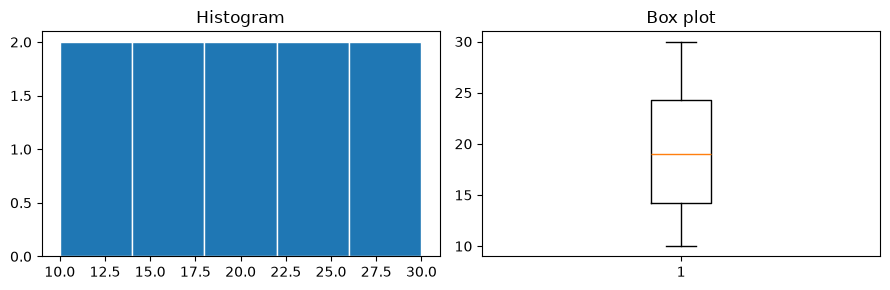

In [6]:
a=np.array([70,72,71]); b=np.array([45,73,95])
print(a.mean(),b.mean(), a.std(),b.std())
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].hist(x,bins=5,edgecolor='white'); axes[0].set_title('Histogram')
axes[1].boxplot(x); axes[1].set_title('Box plot')
plt.tight_layout(); plt.show()

**해석 포인트:** 오른쪽의 큰 값 40과 긴 꼬리, 중앙 50%의 퍼짐은 평균 하나로 알 수 없습니다. bins를 바꾸어도 결론이 안정적인지 확인합니다.

**직접 확인:** 대응 실습의 문제 5에서 다른 입력으로 적용해 보세요.

## 복습 순서

1. 관측 대상과 통계량의 의미를 말로 설명합니다.
2. 분모·단위·독립성·분포 가정을 확인합니다.
3. 직접 계산과 라이브러리 결과를 비교합니다.
4. 코드 결과와 실제로 주장할 수 있는 범위를 구분합니다.

**학습 이동:** `Statistics_1_descriptive.ipynb` → `Statistics_1_descriptive_Practice.ipynb` → `Statistics_1_descriptive_Answer.ipynb`.